# Notebook 3 — LoRA fine-tuning of Llama 3 8B on Mohler (5 question-grouped folds)  ·  GPU: T4

For each fold: fine-tune on that fold's *train* questions, choose the checkpoint with the lowest validation NLL (evaluated twice per epoch on the fold's *val* questions), then score the fold's *val* and *test* answers. Val predictions are kept for calibration and fusion; test predictions give the reported results.

- Same prompt as the zero-shot runs; target = integer score "0"–"10" + EOS; **loss only on the target tokens**.
- LoRA r=16, α=16, all attention and MLP projections; 2 epochs; lr 2e-4 (linear decay, 5% warm-up); batch 8; fp16; seed = 42 + fold.
- Scoring identical to Notebook 1 (probability-weighted score over the tokens 0–10).

**Sessions:** a fold takes ~30–40 min (the first fold prints the real speed). The notebook stops *before* starting a fold once `BUDGET_H` hours have passed, so no fold is cut off; in the next session just run all cells again and it continues with the remaining folds. A fold interrupted by a disconnect restarts from its beginning.

**Before running:** upload the updated `llm_utils.py` (it now contains the training code). T4 runtime.

In [1]:
import time
SESSION_START = time.time()
BUDGET_H = 2.0      # do not START a new fold after this many hours in the session

from google.colab import drive
drive.mount('/content/drive')
import os, sys
ROOT = '/content/drive/MyDrive/asag_revision'
sys.path.insert(0, ROOT)
os.makedirs(f'{ROOT}/models', exist_ok=True)
!nvidia-smi --query-gpu=name,memory.total --format=csv

Mounted at /content/drive
name, memory.total [MiB]
Tesla T4, 15360 MiB


In [2]:
!pip -q install -U bitsandbytes accelerate peft

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 22.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 36.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 832.9/832.9 kB 61.8 MB/s eta 0:00:00


In [3]:
import json, gc, platform
import numpy as np, pandas as pd, torch, transformers, bitsandbytes, peft
from tqdm.auto import tqdm
from asag_utils import *
from llm_utils import *

versions = {'python': platform.python_version(), 'torch': torch.__version__, 'transformers': transformers.__version__,
            'bitsandbytes': bitsandbytes.__version__, 'peft': peft.__version__, 'gpu': torch.cuda.get_device_name(0)}
mo = pd.read_csv(f'{ROOT}/data/mohler_prepared.csv')
prompts = make_prompts(mo, 'mohler')
done = [k for k in range(N_FOLDS) if os.path.exists(f'{ROOT}/results/mohler_llama3_ft_f{k}.csv')]
print('Folds already finished:', done)

Folds already finished: [0, 1, 2, 3]


## 1. Train and predict, fold by fold

In [4]:
lp_cols = [f'lp_{s}' for s in SCORE_TARGETS]

for k in range(N_FOLDS):
    out = f'{ROOT}/results/mohler_llama3_ft_f{k}.csv'
    if os.path.exists(out):
        continue
    used = (time.time() - SESSION_START) / 3600
    if used > BUDGET_H:
        print(f'{used:.2f} h used in this session: stopping before fold {k}. Re-run all cells in a new session.'); break
    print(f'==================== fold {k} ====================')
    t_fold = time.time()
    model, tok = load_hf_4bit(BASE_MODEL)
    cand, _ = candidate_ids(tok, SCORE_TARGETS)
    model, n_trainable = add_lora(model, seed=SEED + k)

    split = mo[f'split_f{k}']
    tr, va, te = mo[split == 'train'], mo[split == 'val'], mo[split == 'test']
    ex = build_examples(tok, [prompts[i] for i in tr.index], tr.y_int.astype(str).tolist())
    # every target must be <score token> + EOS, with the score token equal to the one scored at inference
    assert all(len(t) == 2 and t[0] == cand[y] for (_, t), y in zip(ex, tr.y_int)), 'target tokenisation mismatch'
    print(f'train {len(tr)}  val {len(va)}  test {len(te)}  trainable params {n_trainable:,}  '
          f'max length {max(len(p) + len(t) for p, t in ex)} tokens')

    val_texts, vy_int, vy = [prompts[i] for i in va.index], va.y_int.values, va.y.values
    def evaluate():
        lp = candidate_logprobs(model, tok, val_texts, cand, batch_size=8)
        e, _, m = score_from_logprobs(lp)
        return {'val_nll': float(-lp[np.arange(len(vy_int)), vy_int].mean()),
                'val_pearson': float(np.corrcoef(e, vy)[0, 1]), 'val_mae': float(np.abs(e - vy).mean()),
                'val_mass': float(m.mean())}

    torch.cuda.reset_peak_memory_stats()
    hist, best = train_lora(model, tok, ex, evaluate, seed=SEED + k)
    model.save_pretrained(f'{ROOT}/models/mohler_llama3_ft_f{k}')

    rows = pd.concat([va, te])
    lp = candidate_logprobs(model, tok, [prompts[i] for i in rows.index], cand, batch_size=8)
    e, a, m = score_from_logprobs(lp)
    res = pd.DataFrame({'uid': rows.uid.values, 'split': split[rows.index].values, 'fold': k,
                        'expected': e, 'argmax': a, 'valid_mass': m})
    res = pd.concat([res, pd.DataFrame(lp, columns=lp_cols)], axis=1)

    hist.update(fold=k, n_train=len(tr), n_val=len(va), n_test=len(te), trainable_params=n_trainable, best=best,
                peak_vram_gb=torch.cuda.max_memory_allocated() / 1e9, fold_minutes=(time.time() - t_fold) / 60)
    json.dump(hist, open(f'{ROOT}/results/nb3_trainlog_f{k}.json', 'w'), indent=1, default=float)
    res.to_csv(out, index=False)            # written last: its existence marks the fold as finished
    print(f'fold {k} done in {hist["fold_minutes"]:.1f} min; best checkpoint at epoch {best["epoch"]:.1f}; '
          f'val Pearson {best["val_pearson"]:.3f}')
    del model; gc.collect(); torch.cuda.empty_cache()

==================== fold 4 ====================


config.json:   0%|          | 0.00/1.25k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/50.6k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 5.70GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/198 [00:00<?, ?B/s]

224 4-bit layers; compute dtype before: ['torch.bfloat16'] -> torch.float16
train 1557  val 274  test 442  trainable params 41,943,040  max length 339 tokens
step 50/390  loss 0.7949  3.83s/step
eval {'step': 98, 'epoch': 0.5025641025641026, 'val_nll': 1.3748407363891602, 'val_pearson': 0.7793273153008392, 'val_mae': 1.014007915140882, 'val_mass': 0.9968377351760864}
step 100/390  loss 0.6591  4.70s/step
step 150/390  loss 0.6765  4.68s/step
eval {'step': 195, 'epoch': 1.0, 'val_nll': 1.3288061618804932, 'val_pearson': 0.7609016048529108, 'val_mae': 1.040394706679693, 'val_mass': 0.9976394772529602}
step 200/390  loss 0.5302  4.98s/step
step 250/390  loss 0.4802  4.91s/step
eval {'step': 292, 'epoch': 1.4974358974358974, 'val_nll': 1.3623380661010742, 'val_pearson': 0.8049464248697832, 'val_mae': 0.9135062032121866, 'val_mass': 0.999081552028656}
step 300/390  loss 0.3621  5.03s/step
step 350/390  loss 0.4297  4.96s/step
eval {'step': 390, 'epoch': 2.0, 'val_nll': 1.4206043481826782, '

## 2. Results (runs once all 5 folds are finished)

In [5]:
done = [k for k in range(N_FOLDS) if os.path.exists(f'{ROOT}/results/mohler_llama3_ft_f{k}.csv')]
if len(done) < N_FOLDS:
    print(f'{len(done)}/{N_FOLDS} folds finished: {done}. Run the notebook again in a new session to continue.')
else:
    from sklearn.linear_model import LinearRegression
    ft = pd.concat([pd.read_csv(f'{ROOT}/results/mohler_llama3_ft_f{k}.csv') for k in range(N_FOLDS)])
    preds = pd.read_csv(f'{ROOT}/results/mohler_preds.csv')
    test = ft[ft.split == 'test'].set_index('uid')
    assert len(test) == len(preds) and set(test.index) == set(preds.uid)
    cal = {}
    for k in range(N_FOLDS):          # rescaling fitted on the fold's VALIDATION predictions only
        v = ft[(ft.fold == k) & (ft.split == 'val')].merge(mo[['uid', 'y']], on='uid')
        lr = LinearRegression().fit(v[['expected']], v.y)
        t = test[test.fold == k]
        cal.update(dict(zip(t.index, np.clip(lr.predict(t[['expected']]), 0, 10))))
    preds['llama3_ft'] = preds.uid.map(test.expected)
    preds['llama3_ft_cal'] = preds.uid.map(cal)
    preds.to_csv(f'{ROOT}/results/mohler_preds.csv', index=False)

    rows = [{'system': s, **summarise(preds.y, preds[s], reg_metrics, groups=preds.group, folds=preds.fold)}
            for s in ['llama3_ft', 'llama3_ft_cal']]
    nb3 = pd.DataFrame(rows); nb3.to_csv(f'{ROOT}/results/mohler_nb3_summary.csv', index=False)
    ref = pd.concat([pd.read_csv(f'{ROOT}/results/mohler_nb0_summary.csv'), pd.read_csv(f'{ROOT}/results/mohler_nb1_summary.csv')])
    keep = ['mean', 'minilm_cos', 'composite_fixed_cal', 'llama3_base_zs_cal', 'llama3_instruct_zs',
            'llama3_instruct_zs_cal', 'human_grader1_vs_grader2']
    cols = ['system', 'pearson', 'pearson_ci', 'spearman', 'mae', 'rmse', 'qwk', 'pearson_fold_mean', 'pearson_fold_std']
    display(pd.concat([ref[ref.system.isin(keep)], nb3])[cols].round(3))

,system,pearson,pearson_ci,spearman,mae,rmse,qwk,pearson_fold_mean,pearson_fold_std
0,mean,NaN,NaN,NaN,1.803,2.215,NaN,NaN,NaN
2,minilm_cos,0.486,"[0.425, 0.545]",0.478,1.474,1.935,0.375,0.496,0.093
4,composite_fixed_cal,0.548,"[0.491, 0.601]",0.565,1.388,1.856,0.433,0.556,0.086
10,human_grader1_vs_grader2,0.597,NaN,0.601,1.496,2.621,0.490,NaN,NaN
1,llama3_base_zs_cal,0.611,"[0.556, 0.664]",0.608,1.349,1.767,0.497,0.612,0.058
2,llama3_instruct_zs,0.673,"[0.623, 0.725]",0.694,1.625,2.116,0.600,0.674,0.073
3,llama3_instruct_zs_cal,0.669,"[0.615, 0.723]",0.688,1.219,1.646,0.592,0.674,0.073
0,llama3_ft,0.765,"[0.718, 0.809]",0.747,0.969,1.433,0.747,0.793,0.039
1,llama3_ft_cal,0.786,"[0.749, 0.821]",0.763,0.985,1.411,0.776,0.792,0.038


## 3. Training cost and learning curves (validation NLL on the score token, validation Pearson)

,fold,train,val,steps,sec_per_step,fold_minutes,peak_vram_gb,trainable_params,best_epoch,best_val_pearson
0,0,1575,257,394,4.352,32.151,7.733,41943040,0.497,0.813
1,1,1535,272,384,4.445,31.047,7.633,41943040,1.000,0.854
2,2,1550,254,388,4.418,31.133,7.737,41943040,1.000,0.832
3,3,1538,280,386,4.448,31.178,7.652,41943040,1.503,0.811
4,4,1557,274,390,5.078,36.774,7.733,41943040,1.000,0.761


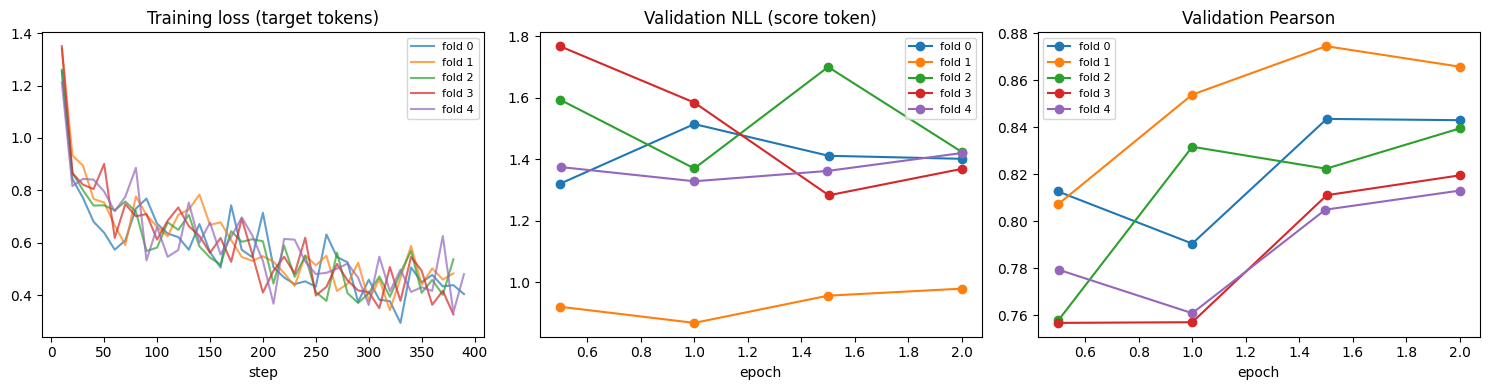

In [6]:
import matplotlib.pyplot as plt
logs = [json.load(open(f'{ROOT}/results/nb3_trainlog_f{k}.json')) for k in range(N_FOLDS)
        if os.path.exists(f'{ROOT}/results/nb3_trainlog_f{k}.json')]
if logs:
    cost = pd.DataFrame([{'fold': h['fold'], 'train': h['n_train'], 'val': h['n_val'], 'steps': h['total_steps'],
                          'sec_per_step': h['sec_per_step'], 'fold_minutes': h['fold_minutes'],
                          'peak_vram_gb': h['peak_vram_gb'], 'trainable_params': h['trainable_params'],
                          'best_epoch': h['best']['epoch'], 'best_val_pearson': h['best']['val_pearson']} for h in logs])
    cost.to_csv(f'{ROOT}/results/nb3_training_cost.csv', index=False)
    display(cost.round(3))

    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    for h in logs:
        tr = pd.DataFrame(h['train']); ev = pd.DataFrame(h['eval'])
        ax[0].plot(tr.step, tr.loss, alpha=.7, label=f"fold {h['fold']}")
        ax[1].plot(ev.epoch, ev.val_nll, 'o-', label=f"fold {h['fold']}")
        ax[2].plot(ev.epoch, ev.val_pearson, 'o-', label=f"fold {h['fold']}")
    for a, t in zip(ax, ['Training loss (target tokens)', 'Validation NLL (score token)', 'Validation Pearson']):
        a.set_title(t); a.legend(fontsize=8)
    ax[0].set_xlabel('step'); ax[1].set_xlabel('epoch'); ax[2].set_xlabel('epoch')
    plt.tight_layout(); plt.savefig(f'{ROOT}/results/fig_mohler_learning_curves.png', dpi=300); plt.show()

In [7]:
json.dump(versions, open(f'{ROOT}/results/env_nb3.json', 'w'), indent=2)
versions

{'python': '3.13.15',
 'torch': '2.11.0+cu128',
 'transformers': '5.16.1',
 'bitsandbytes': '0.50.2',
 'peft': '0.21.0',
 'gpu': 'Tesla T4'}